# Lab 02-03 · Second-Order Linear ODEs

Companion to chapter [02-03](../../chapters/02-03-second-order-linear-odes.md). Handout: [README.md](README.md).

Run the cells in order. Cells marked **🔮 Predict** ask you to write a prediction *before* running.

In [1]:
import math, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass

def simulate(zeta, w0=1.0, y0=0.0, dy0=0.0, X=0.0, T=30.0, n=6001):
    # y'' + 2 zeta w0 y' + w0^2 y = w0^2 X, integrated numerically
    f = lambda t, s: [s[1], w0**2 * (X - s[0]) - 2 * zeta * w0 * s[1]]
    t = np.linspace(0, T, n)
    sol = solve_ivp(f, (0, T), [y0, dy0], t_eval=t, rtol=1e-10, atol=1e-12)
    return t, sol.y[0], sol.y[1]

## Part 1 — Roots and responses

**🔮 Predict:** for ζ = 0.1, how many visible cycles pass before the ring-down falls below 5% of its start?

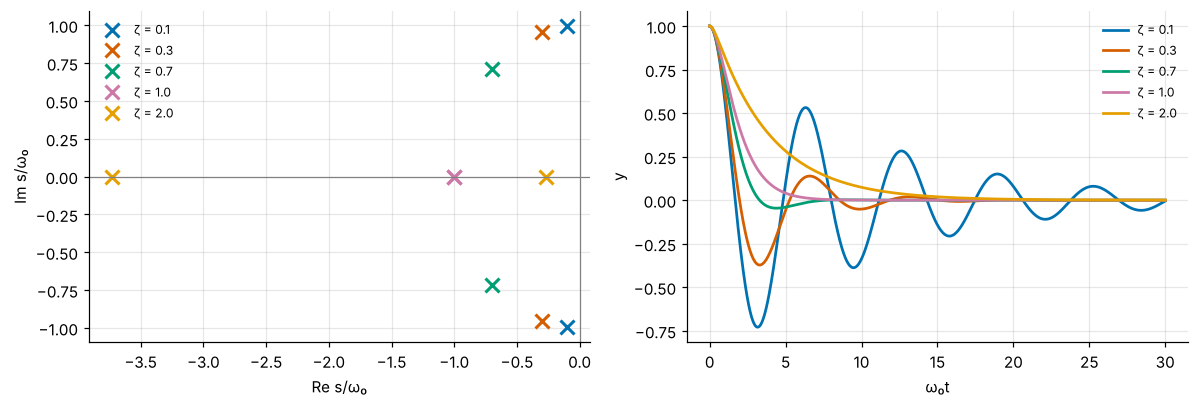

ζ = 0.1: envelope reaches 5% at ω₀t = 30.0, i.e. after 4.74 cycles


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for z in (0.1, 0.3, 0.7, 1.0, 2.0):
    r = np.roots([1, 2 * z, 1])
    axes[0].plot(r.real, r.imag, "x", ms=9, mew=2, label=f"ζ = {z}")
    t, y, _ = simulate(z, y0=1.0)
    axes[1].plot(t, y, label=f"ζ = {z}")
axes[0].axvline(0, color="0.5", lw=0.8); axes[0].axhline(0, color="0.5", lw=0.8)
axes[0].set_xlabel("Re s/ω₀"); axes[0].set_ylabel("Im s/ω₀"); axes[0].legend(fontsize=8)
axes[1].set_xlabel("ω₀t"); axes[1].set_ylabel("y"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

z = 0.1
t5 = math.log(20) / z                      # envelope e^{-ζω₀t} reaches 5%
print(f"ζ = 0.1: envelope reaches 5% at ω₀t = {t5:.1f}, i.e. after {t5 * math.sqrt(1 - z*z) / (2*math.pi):.2f} cycles")

The envelope $e^{-\zeta\omega_0t}$ falls to 5% after $\ln 20/\zeta \approx 30$ radians, about 4.7 cycles. In general the number of cycles to a fraction ε is about $\ln(1/\varepsilon)/(2\pi\zeta) = Q\ln(1/\varepsilon)/\pi$.

## Part 2 — Step-response specifications

We measure overshoot, peak time and 2% settling time from simulated step responses and compare them with the formulas of chapter §3.8.

**🔮 Predict:** which ζ gives the fastest settling into a ±2% band?

In [3]:
def specs(z, tol=0.02):
    t, y, _ = simulate(z, X=1.0, T=60.0, n=60001)
    os_ = max(0.0, y.max() - 1.0)
    tp = t[np.argmax(y)] if z < 1 else float("nan")
    out = np.where(abs(y - 1) > tol)[0]
    ts = t[out[-1] + 1] if out.size else 0.0
    return os_, tp, ts

print(f"{'ζ':>5} {'OS sim %':>9} {'OS formula %':>13} {'t_p sim':>8} {'π/ω_d':>7} {'t_s(2%)':>8}")
for z in (0.3, 0.5, 0.707, 0.78, 1.0, 1.5):
    o, tp, ts = specs(z)
    of = 100 * math.exp(-math.pi * z / math.sqrt(1 - z * z)) if z < 1 else 0.0
    tpf = math.pi / math.sqrt(1 - z * z) if z < 1 else float("nan")
    print(f"{z:5.3f} {100*o:9.3f} {of:13.3f} {tp:8.3f} {tpf:7.3f} {ts:8.3f}")

zz = np.linspace(0.5, 1.2, 71)
best = min(zz, key=lambda z: specs(z)[2])
print(f"\nfastest 2% settling on this grid: ζ ≈ {best:.2f}")

    ζ  OS sim %  OS formula %  t_p sim   π/ω_d  t_s(2%)
0.300    37.233        37.233    3.293   3.293   11.231
0.500    16.303        16.303    3.628   3.628    8.077
0.707     4.325         4.325    4.442   4.442    5.963
0.780     1.992         1.992    5.020   5.020    3.605
1.000     0.000         0.000      nan     nan    5.834
1.500     0.000         0.000      nan     nan   10.655



fastest 2% settling on this grid: ζ ≈ 0.78


Simulation and formulas agree. Settling is fastest near ζ ≈ 0.78, where the overshoot equals exactly 2% (Example 02-03.3), and critical damping is about 1.6 times slower.

## Part 3 — Energy accounting

For the series RLC of Example 02-03.2 ($L$ = 10 µH, $C$ = 1 µF, $R$ = 1 Ω, $v_C(0)$ = 5 V), we track the stored energy and check that it falls at exactly the rate $Ri^2$.

In [4]:
L, Cc, R = 10e-6, 1e-6, 1.0
f = lambda t, s: [s[1] / Cc, (-R * s[1] - s[0]) / L]      # state: v_C, i
t = np.linspace(0, 60e-6, 6001)
sol = solve_ivp(f, (0, 60e-6), [5.0, 0.0], t_eval=t, rtol=1e-11, atol=1e-14)
v, i = sol.y
w = 0.5 * Cc * v**2 + 0.5 * L * i**2
dw = np.gradient(w, t)
print(f"initial energy {w[0]*1e6:.3f} µJ; after 60 µs {w[-1]*1e6:.4f} µJ")
print(f"max |dw/dt + R i²| = {np.max(abs(dw + R * i**2)):.2e} W  (vs typical R i² ~ {np.max(R*i**2):.2e} W)")
print(f"first negative peak of v_C: {v.min():.3f} V at {t[np.argmin(v)]*1e6:.2f} µs")

initial energy 12.500 µJ; after 60 µs 0.0299 µJ
max |dw/dt + R i²| = 8.33e-06 W  (vs typical R i² ~ 1.59e+00 W)
first negative peak of v_C: -3.023 V at 10.06 µs


The only discrepancy is the numerical differentiation error: the stored energy drains exactly through the resistor (chapter §3.11).

## Part 4 — The power-delivery design space

Example 02-03.5: a 10 A step on a 0.75 V rail, with $R$ = 1 mΩ. We map the worst droop over decoupling capacitance $C$ and loop inductance $L$.

**🔮 Predict:** does doubling $C$ or halving $L$ cut the droop more?

base droop: 160.3 mV  (ΔI·√(L/C) = 158.1 mV)
double C:   114.0 mV
halve L:    114.0 mV


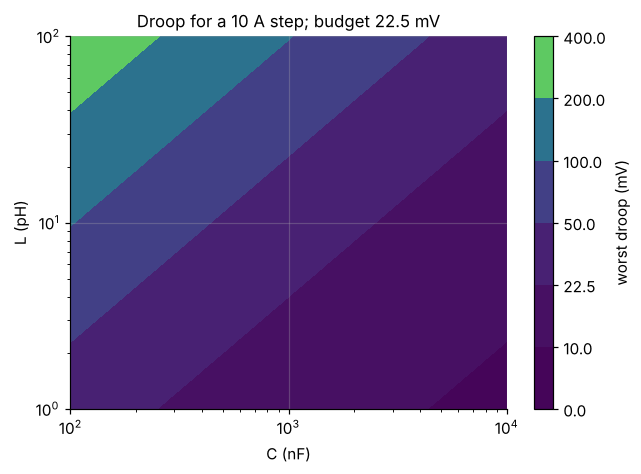

In [5]:
def droop(L, C, R=1e-3, dI=10.0):
    # closed form with complex arithmetic, so it also covers overdamped corners of the grid
    w0 = 1 / math.sqrt(L * C)
    a = R / (2 * L)
    wd = np.sqrt(complex(w0**2 - a**2))
    A = R * dI
    B = (-dI / C + a * R * dI) / wd
    zeta = a / w0
    T = 6 * math.pi / w0 + 10 / (zeta * w0)
    tt = np.linspace(0, min(T, 200 * math.pi / w0), 20001)
    v = (-R * dI + np.exp(-a * tt) * (A * np.cos(wd * tt) + B * np.sin(wd * tt))).real
    return -v.min()

base = droop(25e-12, 100e-9)
print(f"base droop: {base*1e3:.1f} mV  (ΔI·√(L/C) = {10*math.sqrt(25e-12/100e-9)*1e3:.1f} mV)")
print(f"double C:   {droop(25e-12, 200e-9)*1e3:.1f} mV")
print(f"halve L:    {droop(12.5e-12, 100e-9)*1e3:.1f} mV")
Ls = np.logspace(-12, -10, 40); Cs = np.logspace(-7, -5, 40)
D = np.array([[droop(Lx, Cx) * 1e3 for Cx in Cs] for Lx in Ls])
fig, ax = plt.subplots(figsize=(6.4, 4.4))
cs = ax.contourf(Cs * 1e9, Ls * 1e12, D, levels=[0, 10, 22.5, 50, 100, 200, 400], cmap="viridis")
fig.colorbar(cs, label="worst droop (mV)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("C (nF)"); ax.set_ylabel("L (pH)")
ax.set_title("Droop for a 10 A step; budget 22.5 mV"); plt.show()

Doubling $C$ and halving $L$ change $\sqrt{L/C}$ by the same factor, so the droop falls by about $1/\sqrt2$ either way. They differ in what else they do: more $C$ lowers the resonant frequency, less $L$ raises it, which matters for where the impedance peak lands relative to the processor's activity.

## Part 5 — ngspice

From the repository root, run `python tools/run_spice.py 02-03`:

- `rlc_natural.cir`: the ring-down of Example 02-03.2 (first negative peak −3.023 V at 10.06 µs) and the L-to-C energy transfer of Problem 02-03.8 (8.626 V at 147.8 µs);
- `pdn_droop.cir`: the load step of Example 02-03.5 (160.3 mV droop at 2.535 ns) and the 4.938 µF fix (24.95 mV).

## Your turn

1. In Part 2, find the ζ that minimizes 5% settling (instead of 2%), and the overshoot at that ζ.
2. In Part 4, add series resistance $R_{esr}$ to the capacitor instead of the supply path (edit the ODE to have state variables $v_C$ and $i_L$), and find the ESR that minimizes the worst droop.